In [1]:
import pandas as pd 
import numpy as np 
import polars as pl
from typing import List
from collections import Counter
import glob, os

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")

import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 14,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})

import yaml
with open("../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

In [2]:
# ------------------------------------------------------------
# 1. Load your lit-review table
# ------------------------------------------------------------
# Example:
df = pd.read_csv("../../notes/lit-review-framing-261027.csv")
df.columns = df.columns.str.strip().str.lower()
df.head()

,paper,platform(s),research goals,dataset,methodology,main findings,unanswered questions or key limitations,full link,observational window start,observational window end
0,"Broniatowski et al. 2023, ``The efficacy of Fa...",Facebook,Assess whether Facebook’s vaccine misinformati...,710K posts from 216 pages and 100 groups on Fa...,Observational causal / quasi-experimental; per...,Facebook's moderation reduced anti-vaccine pos...,Vaccine misinformation and public Facebook pag...,https://www.science.org/doi/10.1126/sciadv.adh...,2019/11/15; 2020/11/16,2020/11/15; 2022/2/28
1,"Chandrasekharan et al. 2017, ``You can't stay ...",Reddit,Assess whether Reddit's 2015 ban of hateful su...,All posting activity on Reddit in 2015 (around...,Observational causal / quasi-experimental; mat...,Many users of the banned subreddits left the p...,Focused on two communities and the interventio...,https://dl.acm.org/doi/pdf/10.1145/3134666,2015/1/1,2015/12/31
2,"Chandrasekharan et al. 2018, ""The Internet's h...",Reddit,Understand how norms overlap and vary across c...,4.6M moderated comments from Reddit (2.83M com...,Observational descriptive; trained classifiers...,Found both local variation and broader macro n...,Did not analyze the full conversational contex...,https://dl.acm.org/doi/pdf/10.1145/3274301,2016/5/1,2017/3/31
3,"Chandrasekharan et al. 2022, ""Quarantined!"" \c...",Reddit,Evaluate the effects of Reddit's quarantine as...,"Posting activity on r/TheRedPill, r/The\_Donal...",Observational causal / quasi-experimental; per...,Quarantine sharply reduced new-user influx but...,Focused on two communities and immediate effec...,https://dl.acm.org/doi/pdf/10.1145/3490499,2018/4/1; 2018/12/28,2019/3/27; 2019/12/23
4,"Chen et al. 2023, ``Subscriptions and external...",YouTube,Test whether YouTube recommendations drive exp...,"A sample of 1,181 U.S. participants, weighted ...",Observational descriptive; measured exposure t...,Exposure to alternative/extremist videos was c...,Not a direct removal/ban study; mobile/in-app ...,https://www.science.org/doi/pdf/10.1126/sciadv...,2020/7/21,2020/12/31


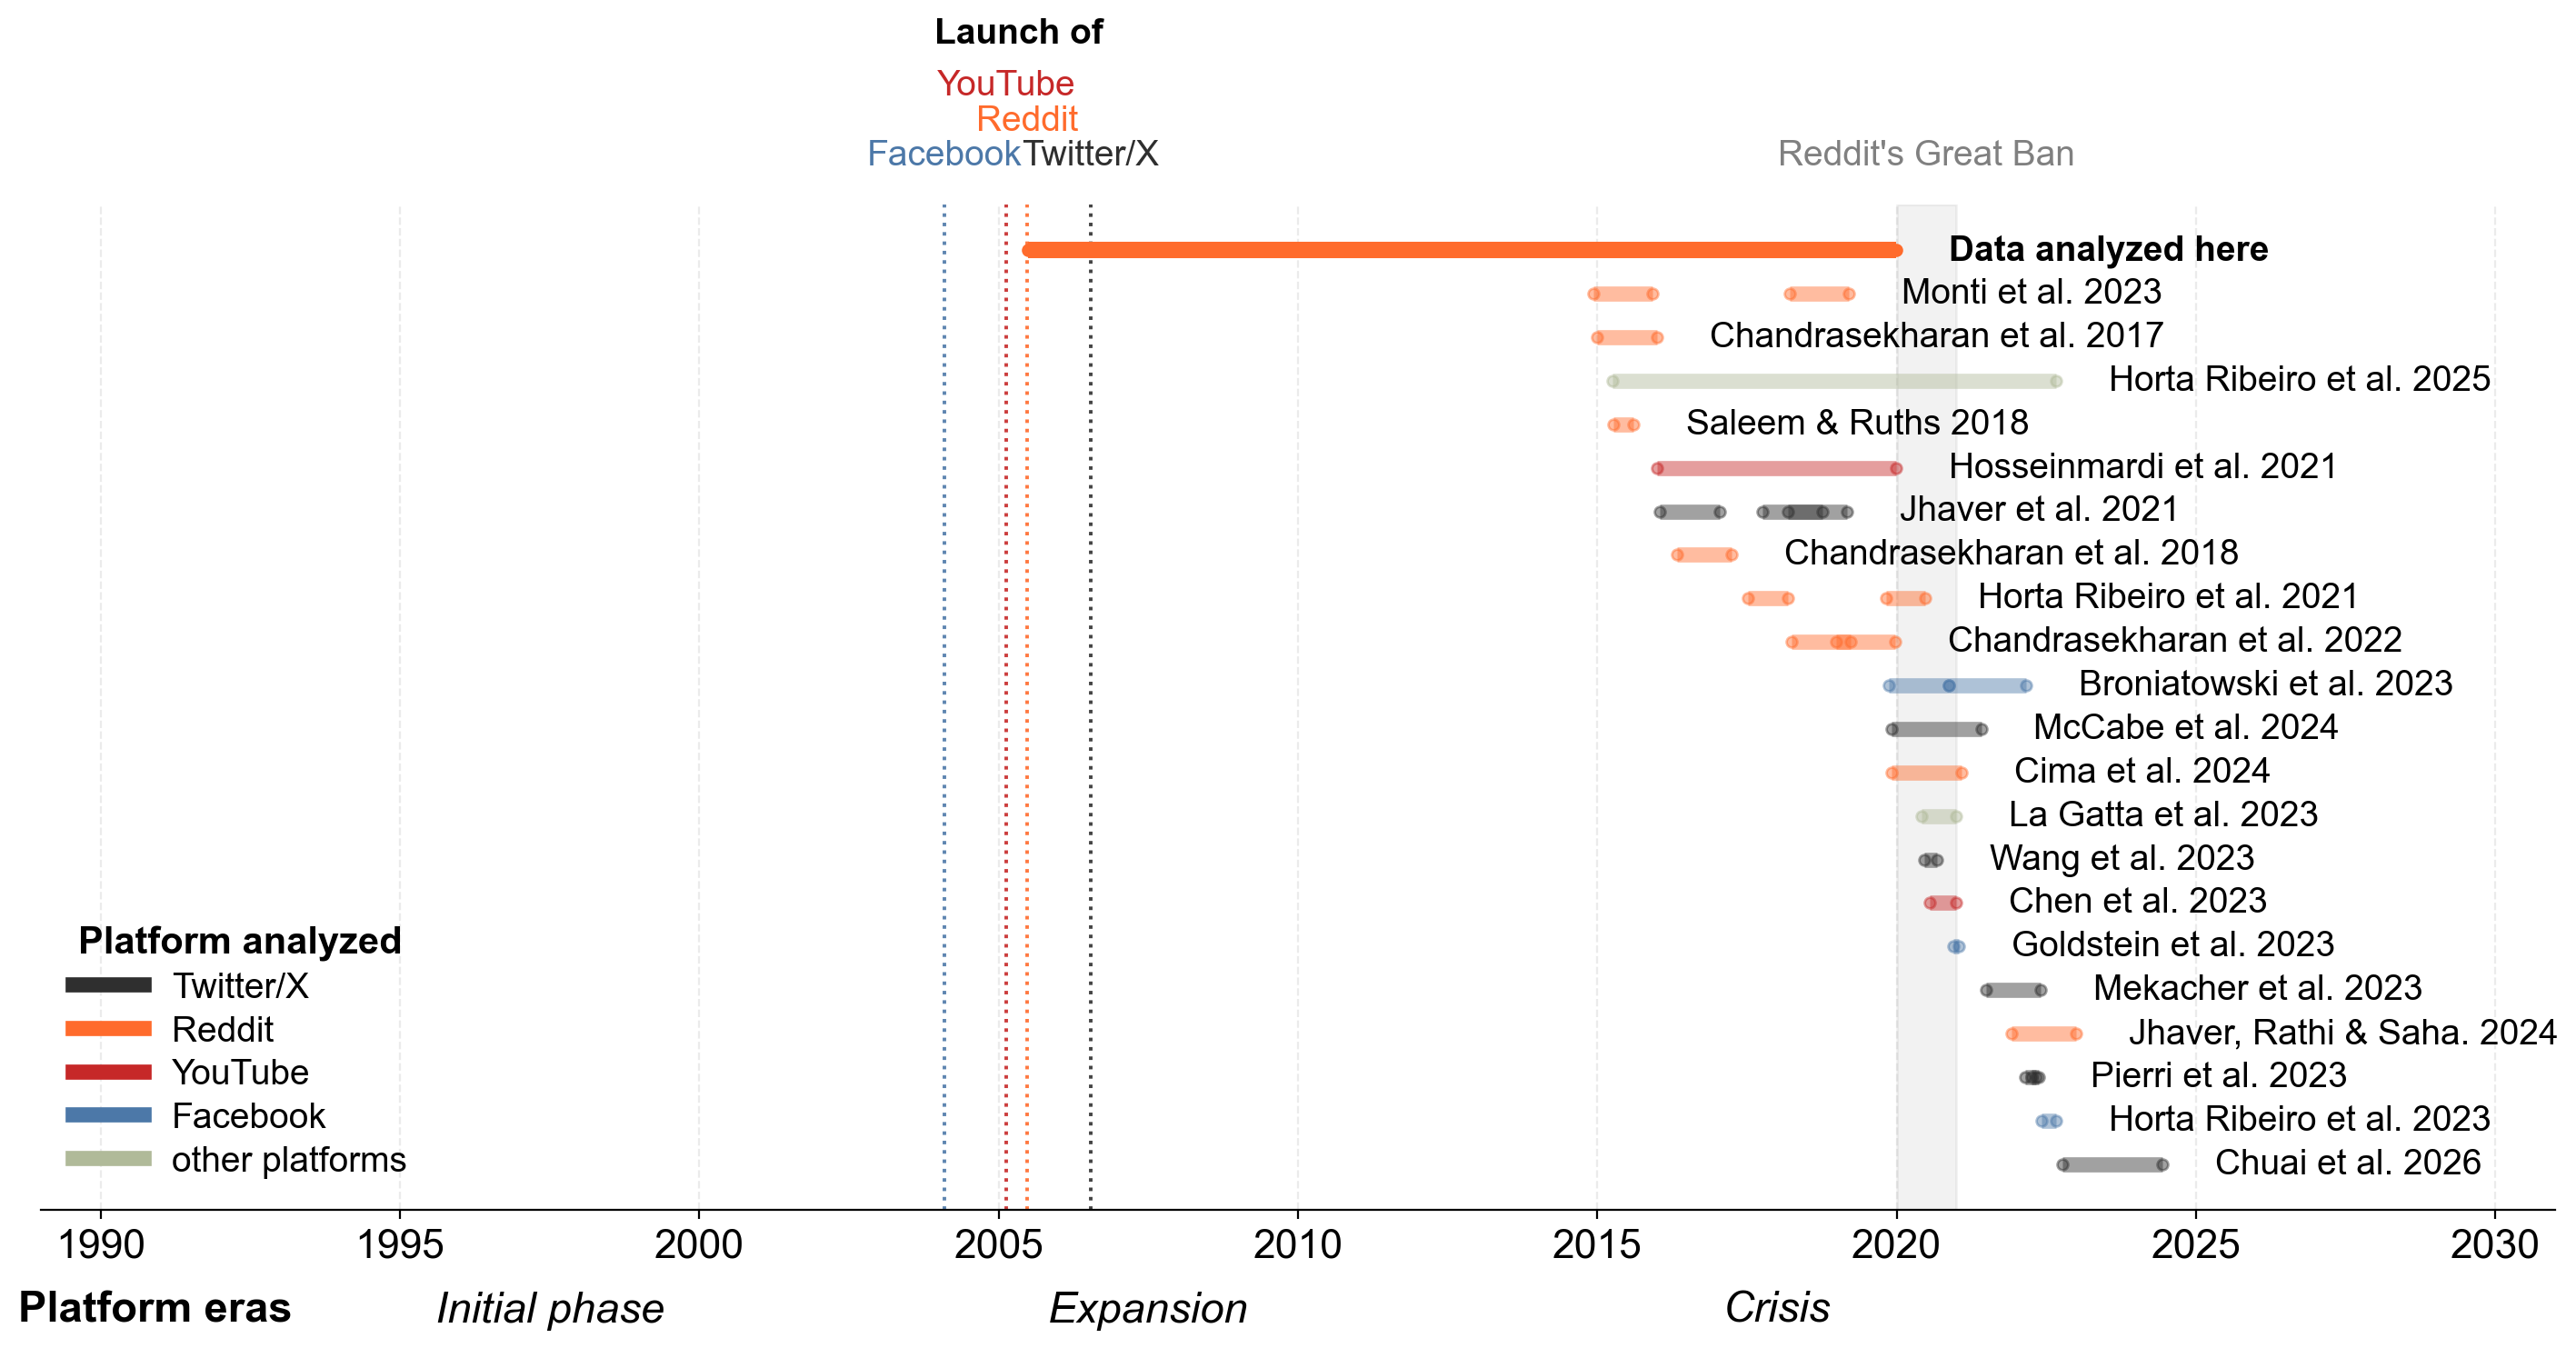

In [3]:

import matplotlib.dates as mdates
from matplotlib.lines import Line2D
import re

# ============================================================
# 2. Helper functions
# ============================================================
# def short_paper_label(paper):
#     """
#     Convert:
#     'McCabe et al. 2024, "Post-January 6th ..."'
#     -> 'McCabe et al. 2024'
#     """
#     if pd.isna(paper):
#         return ""
#     return str(paper).split(",")[0].strip()

def short_paper_label(paper):
    """Return the authors and publication year, preserving author commas."""
    if pd.isna(paper):
        return ""

    text = str(paper).strip()
    match = re.search(r"\b(?:19|20)\d{2}[a-z]?\b", text)
    return text[:match.end()] if match else text


def classify_platform(platform_str):
    """
    Map platform strings into 4 legend groups:
    - Twitter/X
    - Reddit
    - YouTube
    - Other platforms
    """
    if pd.isna(platform_str):
        return "Other platforms"

    p = str(platform_str).lower()

    # exact-ish single-platform priority
    if ("twitter" in p or "x" in p) and ("reddit" not in p) and ("youtube" not in p):
        return "Twitter/X"
    elif "reddit" in p and ("twitter" not in p and "x" not in p) and ("youtube" not in p):
        return "Reddit"
    elif "youtube" in p and ("twitter" not in p and "x" not in p) and ("reddit" not in p):
        return "YouTube"
    elif "facebook" in p:
        return "Facebook"
    else:
        return "Other platforms"

platform_colors = {
    "Twitter/X": "#2f2f2f",
    "Reddit": "#ff6b2c",          
    "YouTube": "#c62828",         
    "Facebook": "#4c78a8",        
    "Other platforms": "#B0BA99",
}


def expand_windows(df):
    """
    Expand rows with semicolon-separated observational windows
    into one row per interval.
    """
    rows = []

    for _, row in df.iterrows():
        starts = str(row["observational window start"]).split(";")
        ends = str(row["observational window end"]).split(";")

        starts = [s.strip() for s in starts if s.strip() not in ["", "nan", "NaN"]]
        ends = [e.strip() for e in ends if e.strip() not in ["", "nan", "NaN"]]

        if len(starts) != len(ends):
            print(f"Skipping row due to mismatched windows: {row['paper']}")
            continue

        for i, (s, e) in enumerate(zip(starts, ends)):
            rows.append({
                "paper": row["paper"],
                "paper_label": short_paper_label(row["paper"]),
                "platforms": row["platform(s)"],
                "platform_group": classify_platform(row["platform(s)"]),
                "start": pd.to_datetime(s),
                "end": pd.to_datetime(e),
                "window_id": i,
                "is_our_project": False
            })

    out = pd.DataFrame(rows)

    # Add "our project"
    our_project = pd.DataFrame([{
        "paper": "our project",
        "paper_label": "Data analyzed here",
        "platforms": "Reddit",
        "platform_group": "Reddit",
        "start": pd.to_datetime("2005-07-01"),
        "end": pd.to_datetime("2019-12-31"),
        "window_id": 0,
        "is_our_project": True
    }])

    out = pd.concat([our_project, out], ignore_index=True)
    return out


# ============================================================
# 3. Prepare plotting data
# ============================================================
plot_df = expand_windows(df)

# Sort papers: our project first, then others by earliest start
paper_order_df = (
    plot_df.groupby(["paper_label", "is_our_project"], as_index=False)["start"]
    .min()
    .sort_values(["is_our_project", "start"], ascending=[False, True])
)

paper_order = paper_order_df["paper_label"].tolist()
paper_to_y = {paper: i for i, paper in enumerate(paper_order)}
plot_df["y"] = plot_df["paper_label"].map(paper_to_y)

# For right-end annotation, only label the rightmost segment for each paper
rightmost_df = (
    plot_df.sort_values("end")
    .groupby("paper_label", as_index=False)
    .tail(1)
    .copy()
)

# ============================================================
# 4. Plot
# ============================================================
fig_height = max(6, 0.28 * len(paper_order) + 1.6)
fig, ax = plt.subplots(figsize=(15, fig_height))

for _, row in plot_df.iterrows():
    color = platform_colors[row["platform_group"]]

    if row["is_our_project"]:
        lw = 6.5
        alpha = 1.0
        z = 3
    else:
        lw = 6
        alpha = 0.45
        z = 2

    ax.hlines(
        y=row["y"],
        xmin=row["start"],
        xmax=row["end"],
        color=color,
        linewidth=lw,
        alpha=alpha,
        zorder=z
    )

    # optional endpoint markers
    ax.scatter(row["start"], row["y"], color=color, s=18, alpha=alpha, zorder=z)
    ax.scatter(row["end"], row["y"], color=color, s=18, alpha=alpha, zorder=z)

# ------------------------------------------------------------
# 5. Add right-end labels
# ------------------------------------------------------------
label_offset = pd.Timedelta(days=320)

for _, row in rightmost_df.iterrows():
    ax.text(
        row["end"] + label_offset,
        row["y"],
        row["paper_label"],
        va="center",
        ha="left",
        # fontsize=16 if row["is_our_project"] else 14,
        fontweight="bold" if row["is_our_project"] else "normal",
        color="black"
    )

# ------------------------------------------------------------
# 6. Platform launch markers + major events
# ------------------------------------------------------------

# Header above the stacked platform launch labels
ax.text(
    pd.to_datetime("2005-05-01"),   # roughly centered over the four launch lines
    -4.6,                           # above YouTube (which is at -3.4)
    "Launch of",
    ha="center",
    va="bottom",
    # fontsize=14,
    fontweight="bold",
    color="black",                  # or "gray" to match the launch styling
    clip_on=False,
)

launch_events = [
    {"label": "Facebook", "date": "2004-02-04", "color": platform_colors["Facebook"]},
    {"label": "YouTube",  "date": "2005-02-14", "color": platform_colors["YouTube"]},
    {"label": "Reddit",   "date": "2005-06-23", "color": platform_colors["Reddit"]},
    {"label": "Twitter/X","date": "2006-07-15", "color": platform_colors["Twitter/X"]},
]

# Shade the year 2020 to indicate the Great Ban period
great_ban_start = pd.to_datetime("2020-01-01")
great_ban_end = pd.to_datetime("2020-12-31")

ax.axvspan(
    great_ban_start,
    great_ban_end,
    color="gray",
    alpha=0.10,
    zorder=0
)

# Label the shaded 2020 band near the top
ax.text(
    pd.to_datetime("2020-07-01"),
    -1.8,
    "Reddit's Great Ban",
    ha="center",
    va="bottom",
    # fontsize=12,
    color="gray"
)

# ------------------------------------------------------------
# Stack launch labels vertically above the plot
# ------------------------------------------------------------
# These are y positions in data coordinates.
# Since the first bar is at y=0 and the axis is inverted,
# negative values place text above the top row.
label_ys = [-1.8, -3.4, -2.6, -1.8]

for event, y_text in zip(launch_events, label_ys):
    date = pd.to_datetime(event["date"])

    # colored dotted vertical line
    ax.axvline(
        date,
        color=event["color"],
        linestyle=":",
        linewidth=1.4,
        alpha=0.9,
        zorder=1
    )

    # stacked horizontal label
    ax.text(
        date,
        # pd.to_datetime("2004-02-04"),
        y_text,
        event["label"],
        ha="center",
        va="bottom",
        # fontsize=12,
        color=event["color"],
        rotation=0
    )

# ------------------------------------------------------------
# 7. Axis formatting
# ------------------------------------------------------------
ax.set_yticks([])
ax.invert_yaxis()

# Fixed overall timeline
xmin = pd.to_datetime("1989-01-01")
xmax = pd.to_datetime("2030-12-31")
ax.set_xlim(xmin, xmax)

# 5-year ticks
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Increase x-axis tick-label size
ax.tick_params(axis="x", labelsize=16)

# ax.set_xlabel("Observational window", fontsize=11)
# ax.set_title("Observational windows in moderation-related studies", fontsize=16, y=1.16)

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.grid(axis="y", visible=False)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

# ------------------------------------------------------------
# 8. Legend
# ------------------------------------------------------------
legend_handles = [
    Line2D([0], [0], color=platform_colors["Twitter/X"], lw=6, label="Twitter/X"),
    Line2D([0], [0], color=platform_colors["Reddit"], lw=6, label="Reddit"),
    Line2D([0], [0], color=platform_colors["YouTube"], lw=6, label="YouTube"),
    Line2D([0], [0], color=platform_colors["Facebook"], lw=6, label="Facebook"),
    Line2D([0], [0], color=platform_colors["Other platforms"], lw=6, label="other platforms"),
    # Line2D([0], [0], color="black", lw=8, alpha=1.0, label="Our project"),
]

ax.legend(
    title="Platform analyzed",
    title_fontproperties={"weight": "bold", "size":15},
    handles=legend_handles,
    loc=3,
    frameon=False,
    labelspacing=0.3
    # fontsize=15,
)

# ------------------------------------------------------------
# 9. Era bands below x-axis
# ------------------------------------------------------------
# We use the x-axis transform so x is in data coordinates,
# and y is in axis coordinates (0 = axis line, negative = below axis).
trans = ax.get_xaxis_transform()

era_bands = [
    {
        "label": "Initial phase",
        "start": "1992-01-01",
        "end": "2002-12-31",   # slightly overlaps into early 2000s
        "y": -0.10, 
        "alpha": 0.10,
    },
    {
        "label": "Expansion",
        "start": "2003-01-01",
        "end": "2011-12-31",   # overlaps both sides
        "y": -0.10, 
        "alpha": 0.10,
    },
    {
        "label": "Crisis",
        "start": "2016-01-01",
        "end": "2019-12-31",   # slightly fuzzy into early 2020s
        "y": -0.10, 
        "alpha": 0.10,
    },
]

# Shared label for the row
ax.text(
    0.1,
    -0.10,
    "Platform eras",
    transform=ax.transAxes,
    ha="right",
    va="center",
    fontsize=17,
    color="black",
    fontweight="bold",
    clip_on=False,
)

# Individual phase labels
for band in era_bands:
    start = pd.to_datetime(band["start"])
    end = pd.to_datetime(band["end"])
    mid = start + (end - start) / 2

    ax.text(
        mid,
        band["y"],
        band["label"],
        transform=trans,
        ha="center",
        va="center",
        fontsize=17,
        color="black",
        fontstyle="italic",
        clip_on=False,
    )
plt.tight_layout()
plt.savefig("../../output/mainbody/lit-review-obs-window.png", dpi=300, bbox_inches="tight")
plt.savefig("../../output/mainbody/lit-review-obs-window.pdf", dpi=300, bbox_inches="tight")